# R6 · Breast block programmes and queries (Fig 6)

For the breast section, this notebook computes:

* **Programmes**, on the whole-section build (`full`: every tile indexed, the layout is built here) and on seeds 0–4. For each
  niche × block it records co-variation within the block, between the block and the rest of the niche, and against random gene sets, plus
  hub genes, Hallmark / GO BP enrichment, the niches' cell types and ACTA2's partners.
* **Queries**, on seeds 0–4: every held-out tile as a whole-tile query (Spindle's top 10 and top 5 against a random 10 and 5, by cell composition; Spindle-naive's for reference),
  with an example query (seed 0). It also runs the 5 breast signatures as gene-list queries (template query, with the
  variance-only and expression controls).

The definitions and pre-registered rules are in `experiments/common/programs.py`.

* **Prerequisites:** `R0_index_cache` (breast_cancer builds and staged inputs), plus the Enrichr GMT files in `~/.cache/gseapy/`
  (MSigDB Hallmark 2020, GO Biological Process 2023).
* **Writes:** `results/breast_programs/{full,seed0..seed4}/`, which holds `blocks.csv`, `enrich_null.csv`, `niche_types.csv`, `acta2.csv`,
  `tile_queries.csv`, `gene_lists.csv` and `gene_list_hits.csv`. `full/` and `seed0/` also hold the figure inputs `corr_niche<k>.npy`, `layout.json`
  and `cells_niche.npz`; `seed0/` also holds `example.csv`, `example_cells.npz` and `signature_cells.npz`.
* **Skips** a build whose outputs exist (`FORCE = True` redoes them).
* **Runtime / memory:** about 10 min; peak about 3 GB.

In [1]:
import gc
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import programs as pg
import results_io as rio
import sections as sx

FORCE = False
TOPIC = "breast_programs"
BUILDS = ["full"] + data.SEEDS
print(data.stamp())


def sub(build):
    return "full" if build == "full" else f"seed{build}"


def done(build, names):
    return not FORCE and all((rio.topic(TOPIC) / sub(build) / n).exists() for n in names)


def save_arrays(build, name, arrays, description):
    path = rio.topic(TOPIC) / sub(build) / name
    np.savez_compressed(path, **arrays)
    rio.register(TOPIC, path, description)


DESC = {
    "blocks": "one row per niche x block: genes, hubs, within / between / null mean |r|, null_p, co-varying, enrichment",
    "enrich_null": "expected enriched fraction of random gene sets per block size",
    "niche_types": "annotated cell types of each niche's index-tile cells vs the section",
    "acta2": "r of ACTA2 with every gene per niche, and whether the gene is in ACTA2's block",
    "tile_queries": "one row per held-out tile: class composition, TV to Spindle's top 10 / top 5, random 10 / random 5, Spindle-naive's top 10 / top 5, expression top 10; Spindle's overlap with Spindle-naive's 10, tiles returned",
    "example": "the example whole-tile query (rule in programs.py): compositions of query, Spindle's top 10, random 10, section, Spindle's top 5, random 5",
    "gene_lists": "one row per signature x query (T template, D variances only, X expression): Cliff's delta, co-variation, Jaccard",
    "gene_list_hits": "the top 10 tiles of every signature x query",
}

{'tag': 'method-v2', 'describe': 'method-v2-1-g06b9e46-dirty', 'commit': '06b9e46'}


## Programmes (`full` and seeds 0–4)

In [2]:
PROG = ["blocks.csv", "enrich_null.csv", "niche_types.csv", "acta2.csv"]
for build in BUILDS:
    if done(build, PROG):
        print(f"{build}: programmes exist, skipped")
        continue
    S = sx.load(pg.KEY, build, parts=pg.PROGRAM_PARTS)
    out = pg.programs(S, build)
    (rio.topic(TOPIC) / sub(build)).mkdir(exist_ok=True)
    for name in ("blocks", "enrich_null", "niche_types", "acta2"):
        rio.write_csv(out[name], TOPIC, f"{sub(build)}/{name}.csv", DESC[name])
    if "corr" in out:
        for k, R in out["corr"].items():
            path = rio.topic(TOPIC) / sub(build) / f"corr_niche{k}.npy"
            np.save(path, R)
            rio.register(TOPIC, path, f"niche {k}'s mean correlation in its gene order (float32)")
        path = rio.topic(TOPIC) / sub(build) / "layout.json"
        path.write_text(json.dumps(out["layout"]))
        rio.register(TOPIC, path, "gene order and blocks per niche, panel genes")
        save_arrays(build, "cells_niche.npz", out["cells_niche"], "every cell: x, y, its tile's niche (-1 = none)")
    del S, out
    gc.collect()

full: programmes exist, skipped
0: programmes exist, skipped
1: programmes exist, skipped
2: programmes exist, skipped
3: programmes exist, skipped
4: programmes exist, skipped


### Summary: co-varying and enriched blocks per niche

In [3]:
summ = []
for build in BUILDS:
    B = pd.read_csv(rio.topic(TOPIC) / sub(build) / "blocks.csv")
    for k, b in B.groupby("niche"):
        summ.append({"build": sub(build), "niche": k + 1, "tiles": b.n_tiles.iloc[0], "blocks": len(b),
                     "co-varying": int(b.covarying.sum()), "enriched": int(b.enriched.sum()),
                     "both": int((b.covarying & b.enriched).sum()), "within (median)": b.within.median(),
                     "between (median)": b.between.median(), "random (median)": b.null_mean.median()})
pd.DataFrame(summ).round(3)

,build,niche,tiles,blocks,co-varying,enriched,both,within (median),between (median),random (median)
0,full,1,760,16,8,6,6,0.063,0.027,0.038
1,full,2,757,17,7,3,3,0.041,0.027,0.037
2,full,3,527,15,6,3,3,0.038,0.023,0.032
3,seed0,1,664,16,6,3,3,0.040,0.027,0.037
4,seed0,2,493,15,7,3,3,0.047,0.023,0.032
5,seed0,3,411,17,9,7,6,0.073,0.029,0.037
6,seed0,4,272,15,6,5,3,0.056,0.027,0.039
7,seed1,1,682,16,8,6,6,0.072,0.027,0.038
8,seed1,2,673,15,6,3,3,0.044,0.027,0.037
9,seed1,3,485,14,6,3,3,0.044,0.022,0.032


### The whole-section build: co-varying blocks of the chosen niche (Fig 6C rule: most blocks both co-varying and enriched)

In [4]:
B = pd.read_csv(rio.topic(TOPIC) / "full" / "blocks.csv")
g = B.assign(both=B.covarying & B.enriched).groupby("niche").agg(both=("both", "sum"), tiles=("n_tiles", "first"))
main = int(g.sort_values(["both", "tiles"], ascending=False).index[0])
print(f"chosen niche {main + 1}; contrast niche {int(g.drop(main).sort_values('tiles', ascending=False).index[0]) + 1}")
B[(B.niche == main) & B.covarying][["block", "size", "hubs", "within", "between", "null_p", "key_term", "key_fdr"]]

chosen niche 1; contrast niche 2


,block,size,hubs,within,between,null_p,key_term,key_fdr
6,6,15,AQP1 PECAM1 VWF,0.236704,0.024944,0.000999,NaN,NaN
8,8,15,CD3E PTPRC CCL5,0.166046,0.033773,0.000999,Allograft Rejection,1.187291e-02
9,9,18,APOC1 CXCL16 PDK4,0.086627,0.029647,0.007992,Microglial Cell Activation (GO:0001774),9.848025e-03
10,10,15,FCER1G LYZ CD4,0.325181,0.039561,0.000999,NaN,NaN
11,11,21,LUM POSTN CCDC80,0.215726,0.033443,0.000999,Epithelial Mesenchymal Transition,7.549027e-07
13,13,15,KRT14 MYLK KRT5,0.269348,0.038367,0.000999,Intermediate Filament Organization (GO:0045109),1.673546e-03
14,14,24,TOP2A RTKN2 PCLAF,0.101710,0.044788,0.000999,G2-M Checkpoint,3.492455e-04
15,15,57,ERBB2 EPCAM CEACAM6,0.258795,0.044047,0.000999,Androgen Response,3.116618e-02


## Queries (seeds 0–4)

In [5]:
QUER = ["tile_queries.csv", "gene_lists.csv", "gene_list_hits.csv"]
for seed in data.SEEDS:
    if done(seed, QUER):
        print(f"seed {seed}: queries exist, skipped")
        continue
    S = sx.load(pg.KEY, seed, parts=pg.QUERY_PARTS)
    out = pg.tile_queries(S, seed) | pg.gene_lists(S, seed)
    for name in ("tile_queries", "gene_lists", "gene_list_hits", "example"):
        if name in out:
            rio.write_csv(out[name], TOPIC, f"seed{seed}/{name}.csv", DESC[name])
    if "example_cells" in out:
        save_arrays(seed, "example_cells.npz", out["example_cells"], "cells (x, y, class) and boxes of the example query and Spindle's top 10")
        save_arrays(seed, "signature_cells.npz", out["signature_cells"], "every cell's score per signature; boxes of the T top 10")
    del S, out
    gc.collect()

example: held-out tile 402 (Myoepithelial 0.36, 35 candidates); top 10 0.37, random 10 0.07, section 0.062
wrote results/breast_programs/seed0/tile_queries.csv: 204 rows
wrote results/breast_programs/seed0/gene_lists.csv: 15 rows
wrote results/breast_programs/seed0/gene_list_hits.csv: 150 rows
wrote results/breast_programs/seed0/example.csv: 6 rows
wrote results/breast_programs/seed1/tile_queries.csv: 204 rows
wrote results/breast_programs/seed1/gene_lists.csv: 15 rows
wrote results/breast_programs/seed1/gene_list_hits.csv: 150 rows
wrote results/breast_programs/seed2/tile_queries.csv: 204 rows
wrote results/breast_programs/seed2/gene_lists.csv: 15 rows
wrote results/breast_programs/seed2/gene_list_hits.csv: 150 rows
wrote results/breast_programs/seed3/tile_queries.csv: 204 rows
wrote results/breast_programs/seed3/gene_lists.csv: 15 rows
wrote results/breast_programs/seed3/gene_list_hits.csv: 150 rows
wrote results/breast_programs/seed4/tile_queries.csv: 204 rows
wrote results/breast_p

### Summary: whole-tile queries (composition difference TV; lower = more alike)

,queries,tv_spindle,tv_random,tv_spindle5,tv_random5,tv_naive5,tv_expr,spindle_in_naive,found_below5,below_random,below_random5
seed,,,,,,,,,,,
0,204,0.156,0.531,0.153,0.543,0.123,0.108,3.0,5,0.975,0.975
1,204,0.146,0.525,0.143,0.544,0.132,0.101,4.0,3,0.985,0.985
2,204,0.144,0.569,0.129,0.574,0.125,0.098,3.0,6,0.975,0.975
3,204,0.149,0.529,0.151,0.539,0.131,0.109,4.0,3,0.975,0.975
4,204,0.169,0.537,0.166,0.552,0.141,0.101,4.0,5,0.975,0.966


     set  Invasive tumour  DCIS  Myoepithelial  Stromal  Endothelial / perivascular  Myeloid  T cells  B cells
   query            0.000 0.138          0.359    0.349                       0.021    0.082    0.036    0.015
   top10            0.000 0.123          0.369    0.341                       0.030    0.096    0.033    0.009
random10            0.247 0.170          0.065    0.250                       0.061    0.085    0.092    0.030
 section            0.243 0.155          0.062    0.264                       0.061    0.086    0.097    0.031
    top5            0.000 0.148          0.390    0.298                       0.042    0.092    0.025    0.006
 random5            0.244 0.166          0.069    0.250                       0.058    0.085    0.097    0.030


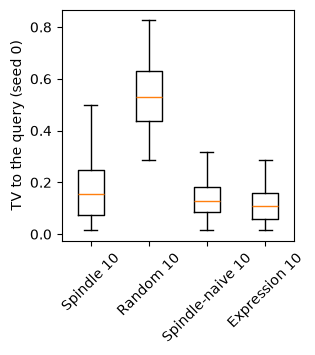

In [6]:
T = pd.concat([pd.read_csv(rio.topic(TOPIC) / f"seed{s}" / "tile_queries.csv").assign(seed=s) for s in data.SEEDS])
display(T.groupby("seed").agg(queries=("query", "size"), tv_spindle=("tv_spindle", "median"),
                              tv_random=("tv_random", "median"), tv_spindle5=("tv_spindle5", "median"),
                              tv_random5=("tv_random5", "median"), tv_naive5=("tv_naive5", "median"),
                              tv_expr=("tv_expr", "median"), spindle_in_naive=("spindle_in_naive", "median"),
                              found_below5=("spindle_found", lambda f: int((f < 5).sum())))
        .assign(below_random=T.groupby("seed").apply(lambda d: (d.tv_spindle < d.tv_random).mean()),
                below_random5=T.groupby("seed").apply(lambda d: (d.tv_spindle5 < d.tv_random5).mean())).round(3))
print(pd.read_csv(rio.topic(TOPIC) / "seed0" / "example.csv").iloc[:, :9].round(3).to_string(index=False))
t0 = T[T.seed == 0]
fig, ax = plt.subplots(figsize=(3, 3))
ax.boxplot([t0.tv_spindle.dropna(), t0.tv_random, t0.tv_naive, t0.tv_expr], showfliers=False)
ax.set_xticks([1, 2, 3, 4], ["Spindle 10", "Random 10", "Spindle-naive 10", "Expression 10"], rotation=45)
ax.set_ylabel("TV to the query (seed 0)")
plt.show()

### Summary: gene-list queries (mean ± s.d. over seeds)

In [7]:
G = pd.concat([pd.read_csv(rio.topic(TOPIC) / f"seed{s}" / "gene_lists.csv").assign(seed=s) for s in data.SEEDS])
G.groupby(["list", "query"])[["delta", "cov_top", "cov_all", "lift", "jacc_D", "jacc_X"]].agg(["mean", "std"]).round(3)

delta        cov_top        cov_all         \
                                mean    std    mean    std    mean    std   
list                    query                                               
Basal_Myoepithelial     D      0.883  0.041   0.377  0.042   0.208  0.002   
                        T      0.803  0.012   0.640  0.011   0.208  0.002   
                        X      1.000  0.000   0.380  0.030   0.208  0.002   
Endothelial_Vascular    D      0.887  0.024   0.440  0.053   0.522  0.004   
                        T      0.920  0.014   0.601  0.011   0.522  0.004   
                        X      1.000  0.000   0.669  0.016   0.522  0.004   
Luminal_Tumor_Core      D      0.789  0.023   0.386  0.023   0.403  0.001   
                        T      0.729  0.042   0.425  0.016   0.403  0.001   
                        X      1.000  0.000   0.495  0.018   0.403  0.001   
Macrophage_Myeloid      D      0.691  0.014   0.361  0.021   0.363  0.001   
                        T      0.546  0.029   0.470  0.005   0.363  0.001   
                        X      1.000  0.000   0.374  0.032   0.363  0.001   
Proliferation_Signature D      0.579  0.178   0.485  0.267   0.443  0.004   
                        T      0.739  0.060   0.604  0.017   0.443  0.004   
                        X      1.000  0.000   0.604  0.031   0.443  0.004   

                                lift        jacc_D        jacc_X         
                                mean    std   mean    std   mean    std  
list                    query                                            
Basal_Myoepithelial     D      0.169  0.044  1.000  0.000  0.124  0.029  
                        T      0.432  0.013  0.139  0.062  0.000  0.000  
                        X      0.172  0.029  0.124  0.029  1.000  0.000  
Endothelial_Vascular    D     -0.082  0.056  1.000  0.000  0.042  0.024  
                        T      0.079  0.010  0.153  0.075  0.021  0.029  
                        X      0.147  0.015  0.042  0.024  1.000  0.000  
Luminal_Tumor_Core      D     -0.017  0.022  1.000  0.000  0.000  0.000  
                        T      0.021  0.016  0.542  0.084  0.000  0.000  
                        X      0.092  0.017  0.000  0.000  1.000  0.000  
Macrophage_Myeloid      D     -0.002  0.022  1.000  0.000  0.011  0.024  
                        T      0.107  0.005  0.139  0.056  0.000  0.000  
                        X      0.011  0.031  0.011  0.024  1.000  0.000  
Proliferation_Signature D      0.042  0.267  1.000  0.000  0.000  0.000  
                        T      0.161  0.019  0.135  0.127  0.000  0.000  
                        X      0.161  0.030  0.000  0.000  1.000  0.000

In [8]:
rio.write_manifest(TOPIC, "R6_breast_programs.ipynb", inputs=["results/_cache/breast_cancer", "~/.cache/gseapy"],
                   notes="Fig 6 inputs; full = whole-section layout (no tile held out)")

wrote results/breast_programs/manifest.json: 53 files; peak memory 1.0 GB


{'topic': 'breast_programs',
 'notebook': 'R6_breast_programs.ipynb',
 'date': '2026-11-02 03:48',
 'tag': 'method-v2',
 'describe': 'method-v2-1-g06b9e46-dirty',
 'commit': '06b9e46',
 'inputs': ['results/_cache/breast_cancer', '~/.cache/gseapy'],
 'peak_rss_gb': 1.0,
 'notes': 'Fig 6 inputs; full = whole-section layout (no tile held out)',
 'files': {'full/acta2.csv': {'description': "r of ACTA2 with every gene per niche, and whether the gene is in ACTA2's block",
   'rows': 936,
   'bytes': 44683},
  'full/blocks.csv': {'description': 'one row per niche x block: genes, hubs, within / between / null mean |r|, null_p, co-varying, enrichment',
   'rows': 48,
   'bytes': 15546},
  'full/cells_niche.npz': {'description': "every cell: x, y, its tile's niche (-1 = none)",
   'rows': None,
   'bytes': 1108827},
  'full/corr_niche0.npy': {'description': "niche 0's mean correlation in its gene order (float32)",
   'rows': None,
   'bytes': 392004},
  'full/corr_niche1.npy': {'description': "n